# 3 Moondream2

In [1]:
import torch
from PIL import Image
from transformers import AutoModelForCausalLM

In [2]:
# Load quantized model (same API as original Moondream3-preview)
moondream = AutoModelForCausalLM.from_pretrained(
    "vikhyatk/moondream2",
    trust_remote_code=True,
    dtype=torch.bfloat16,
    device_map={"": "cuda"},
)

In [3]:
moondream.compile()  # Critical for fast inference

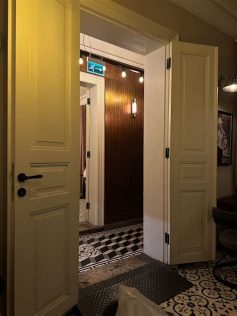

In [4]:
# Load an image
image = Image.open("OIP-3006327341.jpeg")
image.reduce(2)

In [5]:
# Ask a question
result = moondream.query(image=image, question="What's in this image?")
print(result["answer"])

A hallway is captured in the image, bathed in soft, warm light that highlights the yellow doors on the left side. The doors are slightly ajar, revealing the hallway beyond. The hallway has white walls and features two doors on the right side, one of which is slightly ajar as well. 

The floor is adorned with a striking black and white checkered pattern. A small light fixture is mounted on the wall near the right-hand door. There is also a small exit sign visible near the left-hand door. A chair is faintly visible on the right side of the hallway.


In [6]:
# Ask a question
result = moondream.query(image=image, question="Are closed doors in this image?")
print(result["answer"])

No, the image shows open double doors, providing a view into a hallway.


In [7]:
print("\nObject detection: 'door'")
objects = moondream.detect(image, "door")["objects"]
print(f"Found {len(objects)} door(s)")


Object detection: 'door'
Found 2 door(s)


In [8]:
W = image.width; H = image.height
boxes = torch.tensor([[box['x_min']*W, box['y_min']*H, box['x_max']*W, box['y_max']*H] for box in objects], dtype=torch.float)

In [9]:
from torchvision.transforms import v2
image_transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.uint8)])
image_aux = image_transform(image)

In [10]:
from torchvision.utils import draw_bounding_boxes
image_aux2 = draw_bounding_boxes(image_aux, boxes, None, colors="red", width=2)

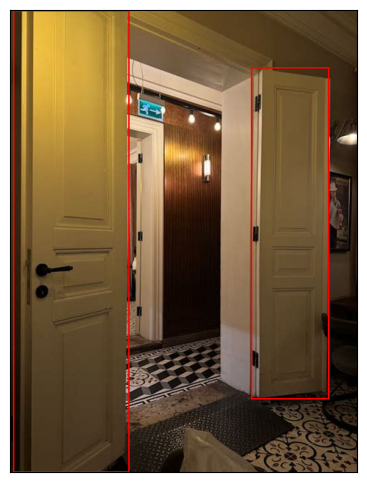

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 6)); plt.xticks([]); plt.yticks([]); 
plt.imshow(image_aux2.permute(1, 2, 0));


<p style="page-break-after:always;"></p>
